In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Standard library test
import time
from pprint import pprint
import glob
import csv
import tqdm
import os

# Third-party libraries
import numpy as np
import matplotlib.pyplot as plt
import scipy
import nibabel as nib
#from jupyterthemes import jtplot; jtplot.style()

# My libraries
from modules.implicit import ImplicitFunction
import modules.utils as utils

## Functions

In [3]:
def polyArea2D(pts):
    # https://stackoverflow.com/questions/19873596/convex-hull-area-in-python
    lines = np.hstack([pts,np.roll(pts,-1,axis=0)])
    area = 0.5*abs(sum(x1*y2-x2*y1 for x1,y1,x2,y2 in lines))
    return area

def ejection_fraction_data(mat: np.ndarray):
    min_volume = np.inf
    max_volume = -np.inf
    for t in range(mat.shape[0]):
        curr = mat[t]
        curr_volume = np.count_nonzero(curr)
        if curr_volume > max_volume:
            max_volume = curr_volume
        if curr_volume < min_volume:
            min_volume = curr_volume
    return ((max_volume - min_volume) / max_volume) * 100

def ejection_fraction_convex(imp: ImplicitFunction):
    constraints4D = imp.data.constraints4D
    min_volume = np.inf
    max_volume = -np.inf
    for t in sorted(constraints4D.keys()):
        curr_volume = 0
        constraints3D = constraints4D[t]
        for z in sorted(constraints3D.keys()):
            boundary_constraints = []
            for pt, pt_dist in constraints3D[z]:
                if pt_dist == 0:
                    boundary_constraints.append(pt[:2])
            # Compute area of boundary constraints
            #print(boundary_constraints)
            curr_volume += polyArea2D(boundary_constraints)
        # Compute volume of current timestep
        if curr_volume > max_volume:
            max_volume = curr_volume
        if curr_volume < min_volume:
            min_volume = curr_volume
    return ((max_volume - min_volume) / max_volume) * 100

def load_acdc(folderpath: str):
    gt_files = sorted(glob.glob(folderpath + "/*_gt.nii.gz"))
    frame1_path = gt_files[0]
    frame2_path = gt_files[1]
    nib_frame1 = nib.load(frame1_path)
    nib_frame2 = nib.load(frame2_path)
    spacing = nib_frame1.header.get_zooms()
    frame1_img = nib_frame1.get_fdata()
    frame2_img = nib_frame2.get_fdata()
    frame1_img = np.moveaxis(frame1_img, -1, 0)
    frame2_img = np.moveaxis(frame2_img, -1, 0)
    spacing = np.moveaxis(spacing, -1, 0)
    print('Frame 1:', frame1_path)
    print('Frame 1 shape:', frame1_img.shape)
    print('Frame 2:', frame2_path)
    print('Frame 2 shape:', frame2_img.shape)
    print('Spacing:', spacing)
    return frame1_img, frame2_img, spacing

## Load data

In [4]:

    
output_csv_path = "output/acdc/acdc-ef-0-50-lv.csv"
all_folders = sorted(glob.glob("data/acdc/training/patient*"))
ef_list = []

# Load into implicit framework
for folder in all_folders[:50]:
    curr_patient = os.path.basename(folder)
    frame1, frame2, spacing = load_acdc(folder)
    data = np.array([frame1, frame2])
    # 1: RV, 2: Myo, 3: LV
    data[data != 3] = 0
    data[data == 3] = 1
    imp = ImplicitFunction(np.array(data), grid_spacing=0.25)
    
    interp0 = imp.interpolate(0)
    interp1 = imp.interpolate(1)
    interpt = np.array([interp0, interp1])
    #np.save('output/acdc/' + curr_patient + '.npy', interpt)
    #ef_interp = -1
    
    # Compute EF
    ef_convex = ejection_fraction_convex(imp)
    ef_interp = ejection_fraction_data(np.array(interpt))
    ef_gt = ejection_fraction_data(data)

    print()
    print('Ejection fraction convex estimation:', ef_convex)
    print('Ejection fraction interpolation estimation:', ef_interp)
    print('Ejection fraction ground truth:', ef_gt)
    print()

    info_dict = {'patient': curr_patient, 
                 'convex': ef_convex, 'interp': ef_interp, 'gt': ef_gt,
                 'convex_diff': ef_convex - ef_gt, 'interp_diff': ef_interp - ef_gt}
    ef_list.append(info_dict)

with open(output_csv_path, 'w', newline='') as csvfile:
    fieldnames = ['patient', 'convex', 'interp', 'gt', 'convex_diff', 'interp_diff']
    writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
    writer.writeheader()
    for d in ef_list:
        writer.writerow(d)

Frame 1: data/acdc/training/patient001/patient001_frame01_gt.nii.gz
Frame 1 shape: (10, 216, 256)
Frame 2: data/acdc/training/patient001/patient001_frame12_gt.nii.gz
Frame 2 shape: (10, 216, 256)
Spacing: [ 1.5625  1.5625 10.    ]
DEBUG: Creating constraints.
(1865, 4)
DEBUG: Finished creating constraints.
Elapsed time: 0.27052998542785645

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/1865 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 0.7013635635375977

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.04819750785827637
Output dimensions: (10, 216, 256)
Threshold: 0.0


Interpolating volume stack:   0%|          | 0/2160 [00:00<?, ?it/s]

Output dimensions: (10, 216, 256)
Threshold: 0.0


...

DEBUG: Finished constructing matrix
Elapsed time: 0.9306440353393555

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.05472588539123535
Output dimensions: (10, 248, 256)
Threshold: 0.0


Interpolating volume stack:   0%|          | 0/2480 [00:00<?, ?it/s]

Output dimensions: (10, 248, 256)
Threshold: 0.0


Interpolating volume stack:   0%|          | 0/2480 [00:00<?, ?it/s]


Ejection fraction convex estimation: 16.584121821407454
Ejection fraction interpolation estimation: 16.090203756072803
Ejection fraction ground truth: 16.44396551724138



Make result plot

Average: 2.7284528208205963
Median: 1.97817000025189
Std: 2.5080296890302214
Min: -12.8166673860977
Max: 10.4229543618136


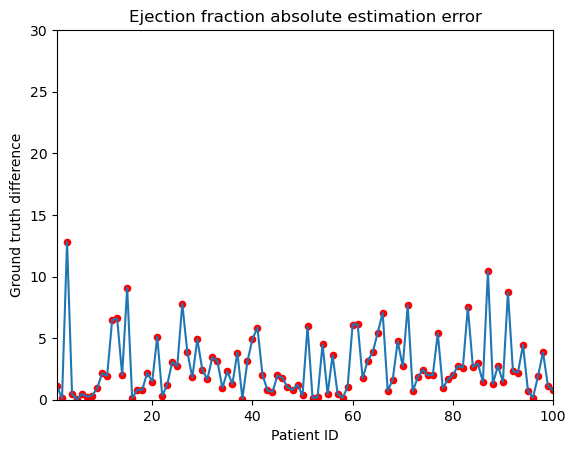

In [19]:
convex_list = []
output_csv_path = "output/acdc/acdc-ef-final.csv"

with open(output_csv_path, 'r', newline='') as csvfile:
    reader = csv.reader(csvfile, delimiter=',', quotechar='|')
    next(reader, None)
    for row in reader:
        convex_list.append(float(row[5]))

abs_convex_list = [abs(ef) for ef in convex_list]
print('Average:', np.mean(abs_convex_list))
print('Median:', np.median(abs_convex_list))
print('Std:', np.std(abs_convex_list))
print('Min:', np.min(convex_list))
print('Max:', np.max(convex_list))
fig = plt.figure()
plt.xlim(1, 100)
plt.ylim(0, 30)
plt.title('Ejection fraction absolute estimation error')
plt.xlabel('Patient ID')
plt.ylabel('Ground truth difference')
plt.plot(range(1, 101), abs_convex_list)
plt.scatter(range(1, 101), abs_convex_list, color='red', s=20)
plt.show()

In [21]:
def metrics(npy_filepath: str, gt_filepath: str):
    if type(npy_filepath) == str:
        curr_npy = np.load(npy_filepath)
    else:
        curr_npy = npy_filepath
    curr_npy[curr_npy != 0] = 1

    if '.nii' in gt_filepath:
        curr_gt = nib.load(gt_filepath).get_fdata()
        curr_gt[curr_gt != 0] = 1
    elif '.npy' in gt_filepath:
        curr_gt = np.load(gt_filepath)
        curr_gt[curr_gt != 0] = 1
    else:
        curr_gt = gt_filepath
        
    if curr_gt.shape[0] - curr_npy.shape[0] == 1:
        curr_gt = curr_gt[:-1]

    curr_dice = utils.dice(curr_npy, curr_gt)
    curr_iou = utils.jaccard(curr_npy, curr_gt)
    curr_precision = utils.precision(curr_npy, curr_gt)
    curr_recall = utils.recall(curr_npy, curr_gt)

    #print('Dice:', curr_dice)
    #print('IoU:', curr_iou)
    #print('Precision:', curr_precision)
    #print('Recall:', curr_recall)
    return curr_dice, curr_iou, curr_precision, curr_recall

# Run metrics
output_dir = "output/acdc/patient*.npy"
output_dir = sorted(glob.glob(output_dir))
all_folders = sorted(glob.glob("data/acdc/training/patient*"))

# Load into implicit framework
dice_list = []
iou_list = []
precision_list = []
recall_list = []
for i in range(len(all_folders[:])):
    curr_out = output_dir[i]
    curr_out = np.load(curr_out)
    folder = all_folders[i]
    curr_frame1 = curr_out[0]
    curr_frame2 = curr_out[1]
    frame1, frame2, spacing = load_acdc(folder)
    
    curr_dice, curr_iou, curr_precision, curr_recall = metrics(curr_frame1, frame1)
    curr_dice2, curr_iou2, curr_precision2, curr_recall2 = metrics(curr_frame2, frame2)
    dice_list.append(curr_dice)
    iou_list.append(curr_iou)
    precision_list.append(curr_precision)
    recall_list.append(curr_recall)
    
    dice_list.append(curr_dice2)
    iou_list.append(curr_iou2)
    precision_list.append(curr_precision2)
    recall_list.append(curr_recall2)
    
print('Average dice:', np.mean(dice_list))
print('Average iou:', np.mean(iou_list))
print('Average precision:', np.mean(precision_list))
print('Average recall:', np.mean(recall_list))

Frame 1: data/acdc/training/patient001/patient001_frame01_gt.nii.gz
Frame 1 shape: (10, 216, 256)
Frame 2: data/acdc/training/patient001/patient001_frame12_gt.nii.gz
Frame 2 shape: (10, 216, 256)
Spacing: [ 1.5625  1.5625 10.    ]
Frame 1: data/acdc/training/patient002/patient002_frame01_gt.nii.gz
Frame 1 shape: (10, 232, 256)
Frame 2: data/acdc/training/patient002/patient002_frame12_gt.nii.gz
Frame 2 shape: (10, 232, 256)
Spacing: [ 1.3671875  1.3671875 10.       ]
Frame 1: data/acdc/training/patient003/patient003_frame01_gt.nii.gz
Frame 1 shape: (10, 256, 256)
Frame 2: data/acdc/training/patient003/patient003_frame15_gt.nii.gz
Frame 2 shape: (10, 256, 256)
Spacing: [ 1.5625  1.5625 10.    ]
Frame 1: data/acdc/training/patient004/patient004_frame01_gt.nii.gz
Frame 1 shape: (10, 232, 256)
Frame 2: data/acdc/training/patient004/patient004_frame15_gt.nii.gz
Frame 2 shape: (10, 232, 256)
Spacing: [ 1.3671875  1.3671875 10.       ]
Frame 1: data/acdc/training/patient005/patient005_frame01_

/tmp/ipykernel_877785/3049968900.py:8: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if '.nii' in gt_filepath:
/tmp/ipykernel_877785/3049968900.py:11: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  elif '.npy' in gt_filepath:


Frame 1: data/acdc/training/patient011/patient011_frame01_gt.nii.gz
Frame 1 shape: (9, 216, 256)
Frame 2: data/acdc/training/patient011/patient011_frame08_gt.nii.gz
Frame 2 shape: (9, 216, 256)
Spacing: [ 1.48438  1.48438 10.     ]
Frame 1: data/acdc/training/patient012/patient012_frame01_gt.nii.gz
Frame 1 shape: (10, 184, 256)
Frame 2: data/acdc/training/patient012/patient012_frame13_gt.nii.gz
Frame 2 shape: (10, 184, 256)
Spacing: [ 1.5625  1.5625 10.    ]
Frame 1: data/acdc/training/patient013/patient013_frame01_gt.nii.gz
Frame 1 shape: (10, 216, 256)
Frame 2: data/acdc/training/patient013/patient013_frame14_gt.nii.gz
Frame 2 shape: (10, 216, 256)
Spacing: [ 1.44531  1.44531 10.     ]
Frame 1: data/acdc/training/patient014/patient014_frame01_gt.nii.gz
Frame 1 shape: (10, 256, 216)
Frame 2: data/acdc/training/patient014/patient014_frame13_gt.nii.gz
Frame 2 shape: (10, 256, 216)
Spacing: [ 1.36719  1.36719 10.     ]
Frame 1: data/acdc/training/patient015/patient015_frame01_gt.nii.gz
F

Frame 1: data/acdc/training/patient050/patient050_frame01_gt.nii.gz
Frame 1 shape: (10, 248, 256)
Frame 2: data/acdc/training/patient050/patient050_frame12_gt.nii.gz
Frame 2 shape: (10, 248, 256)
Spacing: [ 1.3671875  1.3671875 10.       ]
Average dice: 0.8330033446418507
Average iou: 0.7826274818052594
Average precision: 0.8105114089477299
Average recall: 0.8881090325860832


In [23]:
np.max(frame1)

3.0